# Module 10 — Introduction à GeoPandas

**Python pour les SHS**

Ce notebook accompagne les slides du module. On y manipule le **référentiel archéologique de Paris** ([data.gouv.fr](https://www.data.gouv.fr/datasets/referentiel-archeologique-de-paris)) : l'ensemble des opérations archéologiques recensées dans la capitale (fouilles, diagnostics, découvertes anciennes…).

Plan :

1. Charger des données géographiques
2. Les systèmes de coordonnées (CRS)
3. Visualiser
4. Manipulations SIG

Chaque partie se termine par des exercices **À vous de jouer** (les solutions sont repliées sous chaque énoncé).

Prérequis : `pip install geopandas matplotlib folium mapclassify`

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

print(gpd.__version__)

0.14.3


## 1. Charger des données géographiques

### 1.1 Lire un fichier

`gpd.read_file` lit la plupart des formats géographiques (GeoJSON, Shapefile, GeoPackage…).

In [2]:
fouilles = gpd.read_file("../data/referentiel-archeologique-de-paris.geojson")
type(fouilles)

geopandas.geodataframe.GeoDataFrame

In [3]:
fouilles.shape

(1811, 18)

In [4]:
fouilles.head(3)

,id,adresse,code_postal,commune,nature_operation,responsable_operation,date_operation,prehistoire,protohistoire,antiquite,moyen_age,temps_modernes,epoque_contemporaine,synthese,x,y,geo_point_2d,geometry
0,949,4 place Saint-Blaise,75020,Paris,Autres études,Busson Didier,2005,None,Non,Non,Non,Non,Non,"Lors de travaux dans l'église, il est fait sig...",656252.826,6862417.03,"{'lon': 2.4037281443249414, 'lat': 48.86030132...",POINT (2.40373 48.86030)
1,1317,21 rue Cujas,75005,Paris,Découverte ancienne,Vacquer Théodore,1863,None,Non,Oui,Non,Non,Non,"En 1863, à l'occasion de la construction de de...",651717.096,6861080.39,"{'lon': 2.3420608904275384, 'lat': 48.84795698...",POINT (2.34206 48.84796)
2,2264,15 rue de l'Arbre Sec,75001,Paris,Découverte ancienne,Vacquer Théodore,1844,None,Non,Non,Oui,Non,Non,Théodore Vacquer rapporte la découverte en 184...,651717.743,6862380.76,"{'lon': 2.341922031116535, 'lat': 48.859651215...",POINT (2.34192 48.85965)


Un `GeoDataFrame` est un `DataFrame` Pandas avec une colonne spéciale, `geometry`, qui contient les formes géographiques (ici des points).

In [5]:
fouilles.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1811 entries, 0 to 1810
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   id                     1811 non-null   object  
 1   adresse                1811 non-null   object  
 2   code_postal            1811 non-null   object  
 3   commune                1766 non-null   object  
 4   nature_operation       1698 non-null   object  
 5   responsable_operation  1485 non-null   object  
 6   date_operation         1690 non-null   object  
 7   prehistoire            0 non-null      object  
 8   protohistoire          1811 non-null   object  
 9   antiquite              1811 non-null   object  
 10  moyen_age              1811 non-null   object  
 11  temps_modernes         1811 non-null   object  
 12  epoque_contemporaine   1810 non-null   object  
 13  synthese               1803 non-null   object  
 14  x                      1811 non-

In [6]:
# Le type des géométries
fouilles.geom_type.value_counts()

Point    1811
Name: count, dtype: int64

In [7]:
# Une géométrie est un objet shapely : ici un point avec ses coordonnées x (longitude) et y (latitude)
point = fouilles.geometry.iloc[0]
print(point)
print(point.x, point.y)

POINT (2.4037281443249414 48.8603013260788)
2.4037281443249414 48.8603013260788


### 1.2 Tout Pandas reste disponible

Compter, filtrer, créer des colonnes : rien ne change.

In [8]:
fouilles["nature_operation"].value_counts()

nature_operation
Découverte ancienne         1079
Diagnostic                   248
Suivi de travaux             101
Sauvetage urgent              74
Fouille                       68
Sondage                       63
Découverte fortuite           24
Étude documentaire            20
Évaluation archéologique      10
Autres études                  5
Dossier administratif          2
SP                             2
Étude du bâti                  2
Name: count, dtype: int64

In [9]:
# Les périodes sont codées en Oui / Non
periodes = ["protohistoire", "antiquite", "moyen_age", "temps_modernes", "epoque_contemporaine"]
(fouilles[periodes] == "Oui").sum()

protohistoire            37
antiquite               778
moyen_age               639
temps_modernes          430
epoque_contemporaine    100
dtype: int64

In [10]:
# Un filtre renvoie un GeoDataFrame : la géométrie est conservée
antiques = fouilles[fouilles["antiquite"] == "Oui"]
print(type(antiques), len(antiques))

<class 'geopandas.geodataframe.GeoDataFrame'> 778


La date de l'opération est une chaîne de caractères, parfois peu standardisée (`"2019 - 2020"`, `"après 1864"`…). On en extrait une année numérique : c'est du Pandas classique.

In [11]:
fouilles["date_operation"].sample(8, random_state=1).tolist()

['1995', '1922', '1957 - 1958', None, None, '1943', '1914', '2019']

In [12]:
# On garde la première suite de 4 chiffres
fouilles["annee"] = pd.to_numeric(fouilles["date_operation"].str.extract(r"(\d{4})")[0])
fouilles["annee"].describe()

count    1690.000000
mean     1930.604142
std        59.609377
min      1610.000000
25%      1892.000000
50%      1924.000000
75%      1989.000000
max      2020.000000
Name: annee, dtype: float64

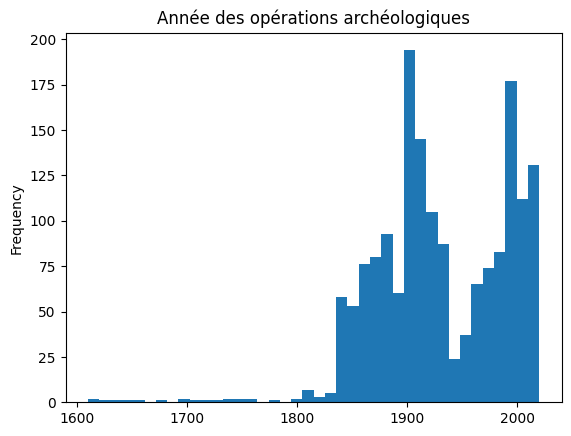

In [13]:
fouilles["annee"].plot.hist(bins=40, title="Année des opérations archéologiques");

### 1.3 Construire un GeoDataFrame à partir d'un tableau

Souvent, on dispose seulement d'un tableau (CSV, Excel) avec deux colonnes de coordonnées. Le même jeu de données existe en CSV, avec des colonnes `X` et `Y`.

In [14]:
df = pd.read_csv("../data/referentiel-archeologique-de-paris.csv", sep=";")
df[["Identifiant", "Adresse", "X", "Y"]].head()

,Identifiant,Adresse,X,Y
0,949,4 place Saint-Blaise,656252.826,6862417.03
1,1317,21 rue Cujas,651717.096,6861080.39
2,2264,15 rue de l'Arbre Sec,651717.743,6862380.76
3,488,10 rue Férou,651128.821,6861217.79
4,2121,1 rue Saint-Séverin,651993.312,6861554.57


Ces coordonnées ne ressemblent pas à des longitudes / latitudes : elles sont exprimées en **Lambert 93** (`EPSG:2154`), le système officiel en France métropolitaine, en mètres. Il faut le préciser en créant la géométrie.

In [15]:
fouilles_csv = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["X"], df["Y"]),
    crs="EPSG:2154",
)
fouilles_csv[["Adresse", "geometry"]].head(3)

,Adresse,geometry
0,4 place Saint-Blaise,POINT (656252.826 6862417.030)
1,21 rue Cujas,POINT (651717.096 6861080.390)
2,15 rue de l'Arbre Sec,POINT (651717.743 6862380.760)


### 1.4 Enregistrer

`to_file` écrit dans le format correspondant à l'extension. Le GeoPackage (`.gpkg`) est un bon choix par défaut : un seul fichier, pas de limite sur les noms de colonnes.

In [16]:
colonnes = ["id", "adresse", "nature_operation", "date_operation", "geometry"]
antiques[colonnes].to_file("fouilles_antiquite.gpkg")

### À vous de jouer (1)

1. Combien d'opérations concernent le **Moyen Âge** ?
2. Qui sont les 5 responsables d'opération les plus fréquents ?
3. Charger le fichier `../data/arrondissements.geojson` dans une variable `arrondissements`. Combien de lignes ? Quel est le type des géométries ?

In [17]:
# Votre code

<details>
<summary>Solution</summary>

```python
# 1.
print((fouilles["moyen_age"] == "Oui").sum())

# 2.
print(fouilles["responsable_operation"].value_counts().head(5))

# 3.
arrondissements = gpd.read_file("../data/arrondissements.geojson")
print(arrondissements.shape)
print(arrondissements.geom_type.value_counts())
```

</details>

## 2. Les systèmes de coordonnées (CRS)

Des coordonnées n'ont de sens qu'avec leur **système de référence** (CRS, *Coordinate Reference System*) :

- **géographique** : longitude / latitude en degrés (ex. WGS 84, `EPSG:4326`, celui du GPS) ;
- **projeté** : coordonnées en mètres sur un plan (ex. Lambert 93, `EPSG:2154`).

In [18]:
fouilles.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [19]:
arrondissements = gpd.read_file("../data/arrondissements.geojson")
arrondissements.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

### 2.1 Reprojeter avec `to_crs`

`to_crs` **recalcule** les coordonnées dans un autre système. (À ne pas confondre avec `set_crs`, qui se contente de *déclarer* le système d'un jeu de données qui n'en a pas.)

In [20]:
fouilles_l93 = fouilles.to_crs("EPSG:2154")
arrondissements_l93 = arrondissements.to_crs("EPSG:2154")

print(fouilles.geometry.iloc[0])
print(fouilles_l93.geometry.iloc[0])

POINT (2.4037281443249414 48.8603013260788)
POINT (656252.8259992129 6862417.033896095)


On retrouve les colonnes `x` et `y` du fichier d'origine :

In [21]:
fouilles_l93[["adresse", "x", "y", "geometry"]].head(3)

,adresse,x,y,geometry
0,4 place Saint-Blaise,656252.826,6862417.03,POINT (656252.826 6862417.034)
1,21 rue Cujas,651717.096,6861080.39,POINT (651717.096 6861080.387)
2,15 rue de l'Arbre Sec,651717.743,6862380.76,POINT (651717.743 6862380.764)


### 2.2 Pourquoi c'est important

Dans un CRS géographique, les mesures sont exprimées en degrés : elles n'ont pas de sens. GeoPandas affiche d'ailleurs un avertissement.

In [22]:
arrondissements.area.head(3)

/var/folders/f9/d2d_05ws5gncmml0fx0c00kw0000gp/T/ipykernel_62737/676163842.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  arrondissements.area.head(3)


0    0.000224
1    0.000122
2    0.000144
dtype: float64

In [23]:
# En Lambert 93 : des m², que l'on convertit en km²
arrondissements_l93["surface_km2"] = arrondissements_l93.area / 1e6
arrondissements_l93[["l_ar", "l_aroff", "surface_km2"]].sort_values("surface_km2", ascending=False).head()

,l_ar,l_aroff,surface_km2
15,16ème Ardt,Passy,16.372542
11,12ème Ardt,Reuilly,16.315417
14,15ème Ardt,Vaugirard,8.494994
12,13ème Ardt,Gobelins,7.148676
18,19ème Ardt,Buttes-Chaumont,6.792651


## 3. Visualiser

### 3.1 Cartes statiques avec `plot`

`plot` s'appuie sur matplotlib.

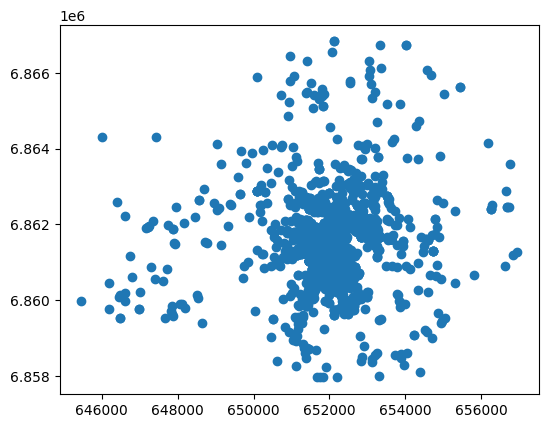

In [24]:
fouilles_l93.plot();

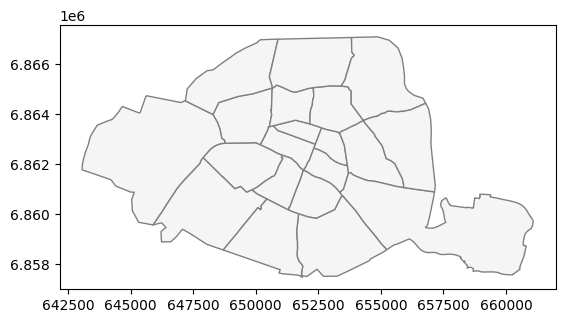

In [25]:
arrondissements_l93.plot(color="whitesmoke", edgecolor="grey");

Pour **superposer** des couches, on les dessine sur le même `ax` (elles doivent partager le même CRS).

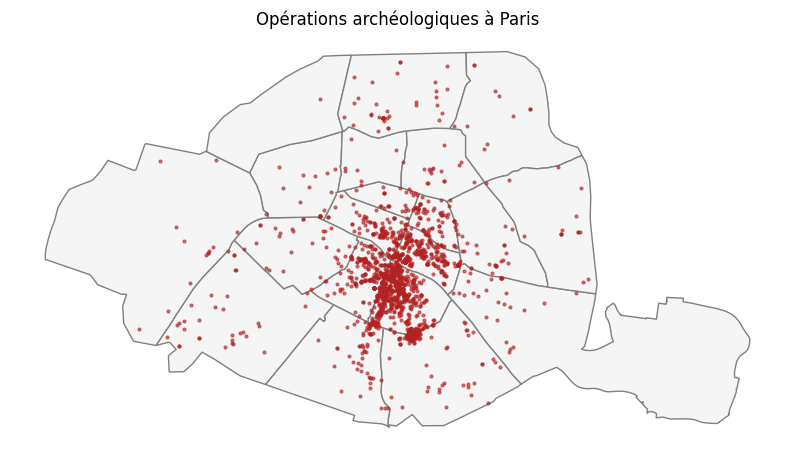

In [26]:
fig, ax = plt.subplots(figsize=(10, 7))
arrondissements_l93.plot(ax=ax, color="whitesmoke", edgecolor="grey")
fouilles_l93.plot(ax=ax, color="firebrick", markersize=4, alpha=0.6)
ax.set_title("Opérations archéologiques à Paris")
ax.set_axis_off()

On peut colorer les entités selon une variable avec `column`.

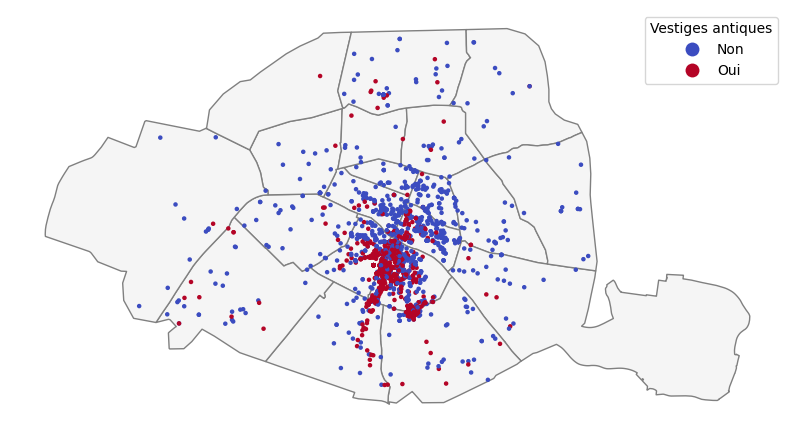

In [27]:
fig, ax = plt.subplots(figsize=(10, 7))
arrondissements_l93.plot(ax=ax, color="whitesmoke", edgecolor="grey")
fouilles_l93.plot(
    ax=ax, column="antiquite", legend=True, markersize=5, cmap="coolwarm",
    legend_kwds={"title": "Vestiges antiques"},
)
ax.set_axis_off()

In [ ]:
# Avec une variable numérique : l'année de l'opération
fig, ax = plt.subplots(figsize=(10, 7))
arrondissements_l93.plot(ax=ax, color="whitesmoke", edgecolor="grey")
fouilles_l93.plot(ax=ax, column="annee", legend=True, markersize=5, cmap="viridis",
                  legend_kwds={"label": "Année de l'opération", "shrink": 0.6})
ax.set_axis_off()

### 3.2 Carte interactive avec `explore`

`explore` produit une carte interactive (bibliothèque `folium`) avec un fond de carte. Très utile pour vérifier ses données.

In [ ]:
fouilles.explore(
    column="nature_operation",
    tooltip=["adresse", "date_operation", "responsable_operation"],
    popup=["adresse", "nature_operation", "date_operation"],
    tiles="CartoDB positron",
)

### À vous de jouer (2 et 3)

1. Faire une carte des opérations concernant le **Moyen Âge**, sur le fond des arrondissements.
2. Ajouter un titre et enregistrer la carte en PNG (`fig.savefig`).
3. Sur la carte interactive, zoomer sur les arènes de Lutèce (5ᵉ arrondissement) : quelles opérations y trouve-t-on ?

In [ ]:
# Votre code

<details>
<summary>Solution</summary>

```python
medievales = fouilles_l93[fouilles_l93["moyen_age"] == "Oui"]

fig, ax = plt.subplots(figsize=(10, 7))
arrondissements_l93.plot(ax=ax, color="whitesmoke", edgecolor="grey")
medievales.plot(ax=ax, color="darkgreen", markersize=5)
ax.set_title("Opérations archéologiques concernant le Moyen Âge")
ax.set_axis_off()
fig.savefig("carte_moyen_age.png", dpi=150, bbox_inches="tight")
```

</details>

## 4. Manipulations SIG

À partir d'ici, on travaille toujours en **Lambert 93** pour que les mesures soient en mètres.

### 4.1 Distances

In [ ]:
from shapely.geometry import Point

# Notre-Dame : longitude, latitude (WGS 84)
notre_dame = gpd.GeoSeries([Point(2.3499, 48.8530)], crs="EPSG:4326").to_crs("EPSG:2154")
notre_dame_point = notre_dame.iloc[0]
print(notre_dame_point)

In [ ]:
fouilles_l93["dist_nd"] = fouilles_l93.distance(notre_dame_point)
fouilles_l93["dist_nd"].describe().round(0)

In [ ]:
# Les 5 opérations les plus proches
fouilles_l93.sort_values("dist_nd")[["adresse", "nature_operation", "annee", "dist_nd"]].head()

### 4.2 Zone tampon (`buffer`)

Une zone tampon est le polygone des points situés à moins d'une certaine distance d'une géométrie.

In [ ]:
zone = notre_dame.buffer(500)   # 500 mètres
proches = fouilles_l93[fouilles_l93.within(zone.iloc[0])]
len(proches)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
arrondissements_l93.plot(ax=ax, color="whitesmoke", edgecolor="grey")
zone.plot(ax=ax, color="steelblue", alpha=0.3)
fouilles_l93.plot(ax=ax, color="grey", markersize=3)
proches.plot(ax=ax, color="firebrick", markersize=6)

# On zoome sur le centre : les axes sont en mètres
x, y = notre_dame_point.x, notre_dame_point.y
ax.set_xlim(x - 1500, x + 1500)
ax.set_ylim(y - 1200, y + 1200)
ax.set_axis_off()

### 4.3 Jointure spatiale (`sjoin`)

La jointure spatiale associe les lignes de deux tableaux selon leur **relation dans l'espace** (et non selon une clé commune). Ici : dans quel arrondissement se trouve chaque fouille ?

In [ ]:
fouilles_arr = gpd.sjoin(fouilles_l93, arrondissements_l93, predicate="within")
fouilles_arr[["adresse", "code_postal", "c_ar", "l_ar", "l_aroff"]].head()

In [ ]:
# Vérification : toutes les fouilles ont trouvé leur arrondissement
print(len(fouilles_l93), len(fouilles_arr))

Le jeu de données contient aussi un code postal : on peut vérifier que la jointure spatiale donne le même résultat.

In [ ]:
arr_code_postal = fouilles_arr["code_postal"].str[-2:].astype(int)
(arr_code_postal == fouilles_arr["c_ar"]).mean()

### 4.4 Agréger par territoire

Une fois la jointure faite, on retrouve le `groupby` de Pandas.

In [ ]:
comptage = fouilles_arr.groupby("c_ar").size().rename("n_fouilles")
comptage.sort_values(ascending=False).head()

In [ ]:
# On rattache le comptage aux polygones par un merge classique
arr_stats = arrondissements_l93.merge(comptage, on="c_ar", how="left")
arr_stats["densite"] = arr_stats["n_fouilles"] / arr_stats["surface_km2"]
arr_stats[["l_ar", "l_aroff", "n_fouilles", "surface_km2", "densite"]].sort_values("densite", ascending=False).head()

### 4.5 Carte choroplèthe

In [ ]:
ax = arr_stats.plot(
    column="densite", cmap="OrRd", edgecolor="white", figsize=(10, 7),
    legend=True, legend_kwds={"label": "Opérations par km²", "shrink": 0.6},
)
ax.set_title("Densité d'opérations archéologiques par arrondissement")
ax.set_axis_off()

La distribution est très asymétrique : quelques arrondissements centraux écrasent l'échelle de couleur. On peut découper les valeurs en **classes** (ici des quantiles) avec le paramètre `scheme` (bibliothèque `mapclassify`).

In [ ]:
ax = arr_stats.plot(
    column="densite", cmap="OrRd", edgecolor="white", figsize=(10, 7),
    scheme="quantiles", k=5, legend=True,
    legend_kwds={"title": "Opérations par km²", "loc": "lower left", "fmt": "{:.0f}"},
)
ax.set_axis_off()

In [ ]:
# Et en version interactive
arr_stats.explore(column="densite", cmap="OrRd", tooltip=["l_ar", "l_aroff", "n_fouilles", "densite"])

### 4.6 Fusionner des géométries (`dissolve`)

`dissolve` est l'équivalent spatial de `groupby` : les géométries d'un même groupe sont fusionnées, et les autres colonnes agrégées.

In [ ]:
arr_stats["rive_gauche"] = arr_stats["c_ar"].isin([5, 6, 7, 13, 14, 15])

rives = arr_stats[["rive_gauche", "n_fouilles", "surface_km2", "geometry"]]
rives = rives.dissolve(by="rive_gauche", aggfunc="sum")
rives

In [ ]:
rives.plot(column="n_fouilles", cmap="OrRd", edgecolor="white", legend=True, figsize=(10, 6)).set_axis_off()

### À vous de jouer (4)

1. Combien d'opérations se trouvent à moins d'**1 km** du Panthéon (longitude 2.3461, latitude 48.8462) ?
2. Quel arrondissement compte le plus d'opérations concernant l'**Antiquité** ? Et le **Moyen Âge** ?
3. Faire la carte choroplèthe de la **part des opérations antérieures à 1900** par arrondissement (parmi les opérations dont l'année est connue).

In [ ]:
# Votre code

<details>
<summary>Solution</summary>

```python
# 1.
pantheon = gpd.GeoSeries([Point(2.3461, 48.8462)], crs="EPSG:4326").to_crs("EPSG:2154")
zone_pantheon = pantheon.buffer(1000).iloc[0]
print(fouilles_l93.within(zone_pantheon).sum())

# 2.
for periode in ["antiquite", "moyen_age"]:
    print(fouilles_arr[fouilles_arr[periode] == "Oui"].groupby("l_ar").size().sort_values(ascending=False).head(3))

# 3.
datees = fouilles_arr.dropna(subset=["annee"]).copy()
datees["avant_1900"] = datees["annee"] < 1900
part = (datees.groupby("c_ar")["avant_1900"].mean() * 100).rename("part_avant_1900")

carte = arrondissements_l93.merge(part, on="c_ar", how="left")
ax = carte.plot(column="part_avant_1900", cmap="Purples", edgecolor="white", legend=True,
                figsize=(10, 7), legend_kwds={"label": "% d'opérations avant 1900", "shrink": 0.6})
ax.set_axis_off()
```

</details>

## Pour aller plus loin

- `gpd.sjoin_nearest` : associer chaque entité à la plus proche d'une autre couche
- `gpd.overlay` : intersection, union, différence entre couches de polygones
- `gdf.clip` : découper une couche selon une emprise
- [Documentation GeoPandas](https://geopandas.org/en/stable/docs/user_guide.html)
- [Geographic Data Science with Python](https://geographicdata.science/book/)

**Une précaution d'interprétation** : cette carte est celle des *opérations archéologiques*, pas celle des vestiges. Elle dépend des chantiers (on fouille là où l'on construit), des époques et des centres d'intérêt des archéologues (Théodore Vacquer, au XIXᵉ siècle, représente à lui seul près d'un quart du référentiel).

Sources : Référentiel archéologique de Paris et contours des arrondissements, Ville de Paris (licence ODbL).